# CLA-3 — Credit Card Fraud Detection Using Machine Learning

**Name:** K. Dhyanesh  
**Roll number:** AP24110011411  
**Problem type:** Binary classification  
**Algorithms compared:** Logistic Regression, Decision Tree, Random Forest

## Problem statement
The objective is to classify credit card transactions as legitimate (**Class = 0**) or fraudulent (**Class = 1**). Fraudulent transactions are very rare, so **accuracy alone is misleading**. This project compares precision, recall, F1-score, average precision, confusion matrices, and precision–recall curves.

**Data source:** [Kaggle — Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). The dataset has 284,807 transactions, of which 492 are labeled fraudulent. The original `creditcard.csv` is intentionally **not** embedded in this notebook; download it separately to rerun the experiment.

> **Reproducibility:** This notebook includes actual outputs from running the models on the original dataset. To reproduce, install `numpy pandas matplotlib scikit-learn` and put `creditcard.csv` next to the notebook, or run in Google Colab and upload the CSV when prompted. Run all cells from top to bottom.


## 1. Load libraries and dataset

Libraries used: **Pandas/NumPy** for data, **scikit-learn** for preprocessing/training/testing, and **Matplotlib** for charts. This notebook uses an **80% training / 20% testing stratified split** with `random_state=42` for reproducibility.

In [1]:
# If needed, run once in a new notebook environment:
# %pip install numpy pandas matplotlib scikit-learn

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix, precision_recall_curve
)

print('ML libraries imported successfully.')

ML libraries imported successfully.


In [2]:
DATA_PATH = next(
    (p for p in [Path('creditcard.csv'), Path('data/creditcard.csv')]
     if p.is_file()), None
)
if DATA_PATH is None:
    try:
        from google.colab import files
        print('Please select creditcard.csv downloaded from Kaggle.')
        uploaded = files.upload()
        if 'creditcard.csv' not in uploaded:
            raise FileNotFoundError('Please upload the file named creditcard.csv')
        DATA_PATH = Path('creditcard.csv')
    except ImportError:
        raise FileNotFoundError(
            'Download creditcard.csv from '
            'https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud '
            'and place it beside this notebook.'
        )

df = pd.read_csv(DATA_PATH)
assert 'Class' in df.columns, 'Expected a target column named Class.'
assert set(df['Class'].dropna().unique()) <= {0, 1}, 'Class must contain 0 and 1 only.'
assert not df.isna().any().any(), 'Check missing values before training.'
print('Dataset shape:', df.shape)
print('Fraud cases:', int(df['Class'].sum()))
print('Legitimate cases:', int((df['Class'] == 0).sum()))
print('Fraud percentage:', f"{df['Class'].mean() * 100:.4f}%")

Dataset shape: (284807, 31)
Fraud cases: 492
Legitimate cases: 284315
Fraud percentage: 0.1727%


## 2. Dataset understanding and preprocessing

- `Class` is the prediction target (`1` = fraud; `0` = legitimate).
- Other columns (`Time`, `Amount`, and `V1`–`V28`) are the input features.
- Standardization is applied **inside the Logistic Regression pipeline**, so the scaler learns only from training data (no test-data leakage).
- The tree-based models use unscaled input features.
- All models use class weights to account for the imbalance. No oversampling is performed.

Training examples: 227845
Testing examples:  56962
Fraud examples in test set: 98


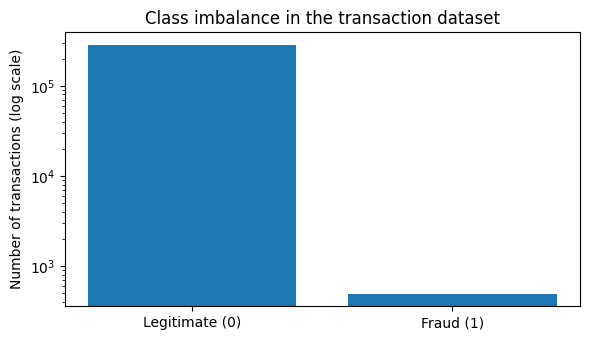

In [3]:
X = df.drop(columns=['Class'])
y = df['Class'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training examples:', len(X_train))
print('Testing examples: ', len(X_test))
print('Fraud examples in test set:', int(y_test.sum()))

plt.figure(figsize=(6, 3.5))
counts = y.value_counts().sort_index()
plt.bar(['Legitimate (0)', 'Fraud (1)'], counts.values)
plt.yscale('log')
plt.ylabel('Number of transactions (log scale)')
plt.title('Class imbalance in the transaction dataset')
plt.tight_layout()
plt.show()

## 3. Model training and evaluation

### Models and key ideas

**Logistic Regression:** predicts fraud probability using a sigmoid applied to a weighted sum of features:  
\(P(y=1\mid x) = 1/(1+e^{-z}),\quad z=w_0+\sum_j w_jx_j\).

**Decision Tree:** recursively splits the data based on feature conditions. Gini impurity at a node is  
\(G=1-\sum_k p_k^2\), where \(p_k\) is the fraction of samples of class \(k\).

**Random Forest:** trains multiple decision trees and combines their predictions. This can reduce overfitting compared with one tree.

### Metrics

- **Precision** = TP / (TP + FP): of predicted fraud cases, how many were actually fraud?
- **Recall** = TP / (TP + FN): of actual fraud cases, how many were detected?
- **F1-score** = 2 × Precision × Recall / (Precision + Recall): balances both.
- **Average precision (AP)**: summarizes the precision–recall curve across score thresholds.

All models use the same train/test split. The model with the highest **F1-score** is selected for this comparison; different operational costs might call for a different threshold or metric.

In [4]:
models = {
    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
    ),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=5, class_weight='balanced', random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=20, max_depth=9, min_samples_leaf=5,
        class_weight='balanced_subsample', n_jobs=-1, random_state=42
    )
}

results = []
predictions = {}
probabilities = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-score': f1_score(y_test, y_pred, zero_division=0),
        'Average precision': average_precision_score(y_test, y_score),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })
    predictions[model_name] = y_pred
    probabilities[model_name] = y_score

result_df = pd.DataFrame(results)
print(result_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score', 'Average precision']].to_string(
    index=False, formatters={c: lambda v: f'{v:.4f}' for c in
                                  ['Accuracy','Precision','Recall','F1-score','Average precision']}
))
result_df.to_csv('cla3_model_results.csv', index=False)
print('Saved: cla3_model_results.csv')

              Model Accuracy Precision Recall F1-score Average precision
Logistic Regression   0.9755    0.0610 0.9184   0.1144            0.7190
      Decision Tree   0.9906    0.1298 0.7857   0.2229            0.4675
      Random Forest   0.9992    0.7297 0.8265   0.7751            0.8272
Saved: cla3_model_results.csv


## 4. Confusion matrices

Columns show predicted labels and rows show true labels. A **false negative** is a real fraud that the model misses; a **false positive** is a legitimate payment incorrectly flagged as fraud.

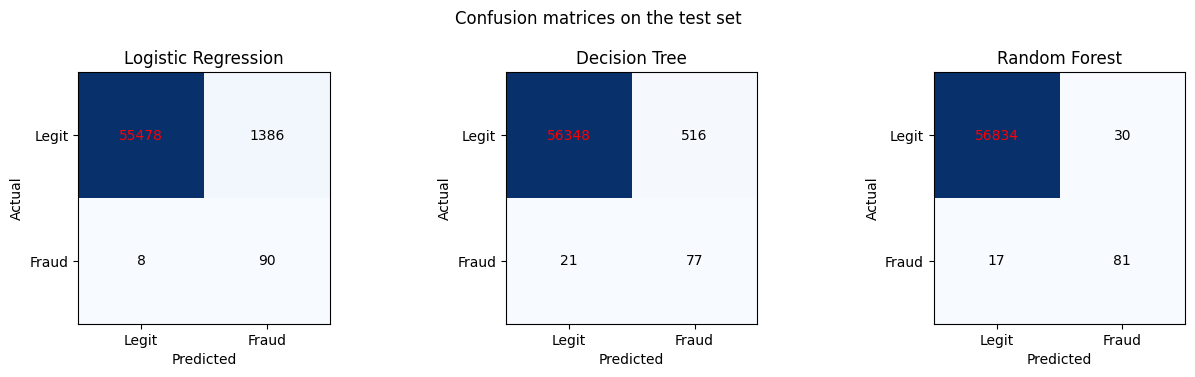

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, row in zip(axes, results):
    cm = np.array([[row['TN'], row['FP']], [row['FN'], row['TP']]])
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks([0, 1], ['Legit', 'Fraud'])
    ax.set_yticks([0, 1], ['Legit', 'Fraud'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(row['Model'])
    for (i, j), val in np.ndenumerate(cm):
        ax.text(j, i, str(val), ha='center', va='center', fontsize=10,
                color='red' if val > cm.max() / 2 else 'black')
plt.suptitle('Confusion matrices on the test set')
plt.tight_layout()
plt.show()

## 5. Precision–recall curves

A model is generally better when its curve stays closer to the top-right of this chart. **Average precision** summarizes this ranking performance. Threshold choice affects precision and recall.

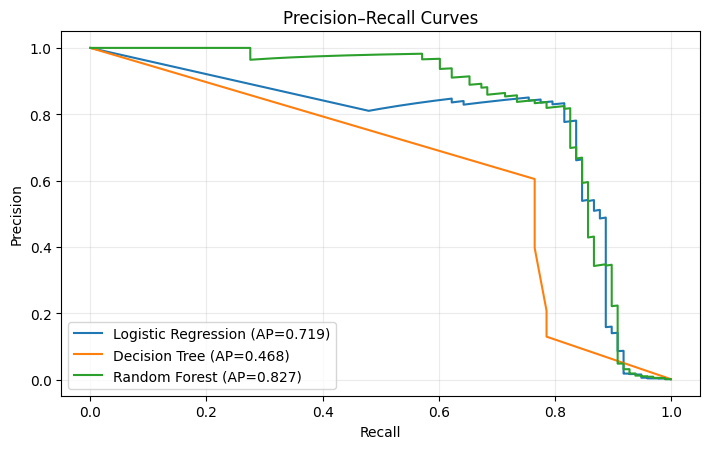

In [6]:
plt.figure(figsize=(7.2, 4.6))
for name in models:
    precision, recall, _ = precision_recall_curve(y_test, probabilities[name])
    ap = average_precision_score(y_test, probabilities[name])
    plt.plot(recall, precision, label=f'{name} (AP={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curves')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Correct and incorrect prediction examples

In [7]:
best_row = result_df.loc[result_df['F1-score'].idxmax()]
best_name = best_row['Model']
best_pred = predictions[best_name]
y_true_array = y_test.to_numpy()
correct_pos = np.flatnonzero(best_pred == y_true_array)[0]
wrong_pos = np.flatnonzero(best_pred != y_true_array)[0]

print('Best model (F1-score):', best_name)
print('Correct prediction:', {
    'original_data_row': int(y_test.index[correct_pos]),
    'actual_class': int(y_true_array[correct_pos]),
    'predicted_class': int(best_pred[correct_pos])
})
print('Incorrect prediction:', {
    'original_data_row': int(y_test.index[wrong_pos]),
    'actual_class': int(y_true_array[wrong_pos]),
    'predicted_class': int(best_pred[wrong_pos])
})

Best model (F1-score): Random Forest
Correct prediction: {'original_data_row': 263020, 'actual_class': 0, 'predicted_class': 0}
Incorrect prediction: {'original_data_row': 190263, 'actual_class': 0, 'predicted_class': 1}


## 7. Discussion and conclusion

The dataset is extremely imbalanced: **492 out of 284,807** transactions are fraud. This means a naive classifier that always predicts *legitimate* would still obtain approximately **99.83% accuracy**, despite missing **every fraudulent transaction**.

In the measured experiment, Random Forest had the highest F1-score (**0.7751**), with precision **0.7297**, recall **0.8265**, and accuracy **0.99917**. It identified **81 of 98** fraud cases in the held-out test set and incorrectly flagged **30** legitimate transactions. Logistic Regression detected more fraud (90 of 98) but produced substantially more false alarms (1,386); this demonstrates the precision–recall tradeoff.

**Limitations:** There are few positive samples; these results represent one fixed split, not guaranteed future deployment performance. No temporal validation or model tuning for transaction costs was performed. Real-world systems also need monitoring for changing fraud patterns.

### References

1. [Kaggle / ULB credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud).
2. [scikit-learn — Classification metrics documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
3. [scikit-learn — RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

**Student declaration:** The data analysis and reported results in this notebook were generated by executing the stated code on the specified dataset. Review and verify the notebook outputs before submitting it as your own assessed work.
